# بخش ۱: شناخت مسئله، تحلیل امضاهای هیدرولیکی و خوشه‌بندی لوله‌ها
این نوت‌بوک خروجی‌های تولیدشده توسط اسکریپت‌های `signatures.py` و `clusters.py` را بارگذاری و تحلیل می‌کند تا جداول، نمودارها و شواهد مورد نیاز گزارش دو صفحه‌ای بخش ۱ را آماده کند.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wntr

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True

HERE = os.getcwd()
ART = os.path.join(HERE, 'artifacts')
INP = os.path.join(HERE, 'network', 'L-TOWN_Model.inp')

# بررسی وجود فایل‌های خروجی اسکریپت‌های بخش ۱
required_files = ['signatures.npz', 'scaling_check.csv', 'k_selection.csv', 'pipe_details.csv', 'leaks_with_clusters.csv', 'cluster_info.json']
missing = [f for f in required_files if not os.path.exists(os.path.join(ART, f))]
if missing:
    print('فایل‌های زیر یافت نشدند. ابتدا signatures.py و سپس clusters.py را اجرا کنید:', missing)
else:
    print('تمام فایل‌های artifacts بخش ۱ آماده هستند.')

تمام فایل‌های artifacts بخش ۱ آماده هستند.


## ۱. بررسی قانون مقیاس‌پذیری اندازه نشت (گام ۳ راهنما)
بررسی اینکه تغییر فشار و افزایش دبی متناسب با مربع قطر روزنه یعنی $(D / 0.015)^2$ رشد می‌کند و محاسبه خطا و محدوده اطمینان.

measured_ratio                         area_rule                       \
                mean     std     min     max      mean  std     min     max   
D                                                                             
0.008         0.2659  0.0470  0.1453  0.3622    0.2844  0.0  0.2844  0.2844   
0.025         2.7122  1.0377 -0.3620  3.3644    2.7778  0.0  2.7778  2.7778   

      rel_error_pct                             
               mean      std     min       max  
D                                               
0.008       11.0603  13.6129  3.5455   48.9220  
0.025       21.9583  29.5928  7.3763  113.0318

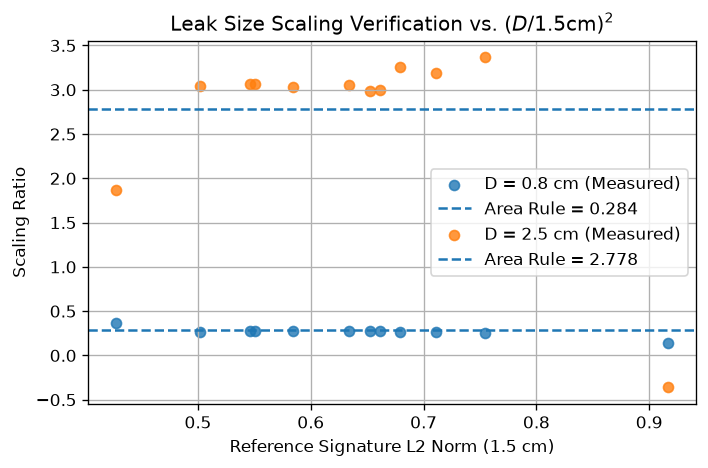

In [7]:
chk_df = pd.read_csv(os.path.join(ART, 'scaling_check.csv'))
chk_df['rel_error_pct'] = 100 * np.abs(chk_df['measured_ratio'] - chk_df['area_rule']) / chk_df['area_rule']

display(chk_df.groupby('D')[['measured_ratio', 'area_rule', 'rel_error_pct']].agg(['mean', 'std', 'min', 'max']).round(4))

fig, ax = plt.subplots(figsize=(6, 4))
for d, grp in chk_df.groupby('D'):
    ax.scatter(grp['ref_norm'], grp['measured_ratio'], label=f'D = {d*100:.1f} cm (Measured)', alpha=0.8)
    ax.axhline(grp['area_rule'].iloc[0], linestyle='--', label=f'Area Rule = {grp["area_rule"].iloc[0]:.3f}')
ax.set_xlabel('Reference Signature L2 Norm (1.5 cm)')
ax.set_ylabel('Scaling Ratio')
ax.set_title(r'Leak Size Scaling Verification vs. $(D/1.5\mathrm{cm})^2$')
ax.legend()
plt.tight_layout()
plt.show()

## ۲. انتخاب تعداد خوشه‌ها ($K$ بین ۱۰ تا ۲۰) و توجیه آن
مقایسه معیارهای Silhouette، تلاش جستجوی مورد انتظار (Expected Search Effort) و دقت انتخاب اول (Top-1) برای مقادیر مختلف $K$.

,K,silhouette,exp_search_effort,exp_top1,max_cluster
0,10,0.7467,0.1445,0.9706,183
1,11,0.6922,0.1243,0.9665,170
2,12,0.6616,0.1091,0.9653,160
3,13,0.6741,0.1050,0.9672,160
4,14,0.6883,0.0985,0.9664,160
5,15,0.6965,0.0960,0.9597,160
6,16,0.6790,0.0899,0.9486,160
7,17,0.7102,0.0921,0.9655,156
8,18,0.6745,0.0804,0.9594,136
9,19,0.7049,0.0864,0.9537,155


تعداد خوشه انتخاب‌شده: K = 14 | آستانه نویز ۹۵٪: 2.62


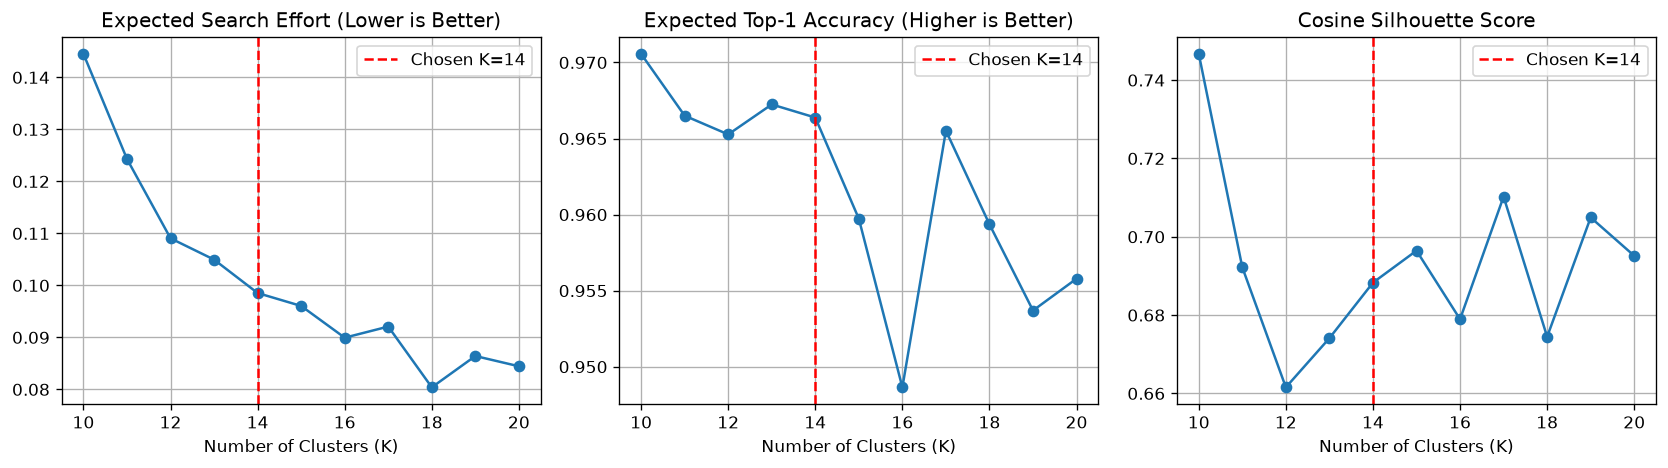

In [3]:
tab = pd.read_csv(os.path.join(ART, 'k_selection.csv'))
info = json.load(open(os.path.join(ART, 'cluster_info.json')))
chosen_K = info['K']

display(tab.round(4))
print(f'تعداد خوشه انتخاب‌شده: K = {chosen_K} | آستانه نویز ۹۵٪: {info["noise_thr_95"]:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = [('exp_search_effort', 'Expected Search Effort (Lower is Better)'),
           ('exp_top1', 'Expected Top-1 Accuracy (Higher is Better)'),
           ('silhouette', 'Cosine Silhouette Score')]

for ax, (col, title) in zip(axes, metrics):
    ax.plot(tab['K'], tab[col], marker='o')
    ax.axvline(chosen_K, color='red', linestyle='--', label=f'Chosen K={chosen_K}')
    ax.set_xlabel('Number of Clusters (K)')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## ۳. تحلیل لوله‌های کم‌اثر (غیرقابل آشکارسازی) و توزیع اندازه خوشه‌ها

In [4]:
pipes_df = pd.read_csv(os.path.join(ART, 'pipe_details.csv'))
leaks_df = pd.read_csv(os.path.join(ART, 'leaks_with_clusters.csv'))
thr_noise = info['noise_thr_95']

low_vis = pipes_df[~pipes_df['detectable_1p2cm']].sort_values('z_norm_1p5cm')
print(f'تعداد کل لوله‌ها: {len(pipes_df)} | تعداد لوله‌های کم‌اثر (زیر نویز در D=1.2cm): {len(low_vis)}')
print('۱۰ لوله با ضعیف‌ترین امضا (نزدیک مخزن / شیر فشارشکن / حسگر جریان):')
display(low_vis.head(10).round(3))

# آمار هر خوشه: تعداد کل لوله‌ها، تعداد لوله‌های قابل تشخیص و تعداد نشت‌های واقعی
summary = pipes_df.groupby('cluster').agg(
    total_pipes=('pipe_id', 'count'),
    detectable_pipes=('detectable_1p2cm', 'sum'),
    median_z_1p5cm=('z_norm_1p5cm', 'median')
)
real_counts = leaks_df['cluster'].value_counts()
summary['real_leaks_2018'] = summary.index.map(real_counts).fillna(0).astype(int)
display(summary)

empty_clusters = summary[summary['real_leaks_2018'] == 0].index.tolist()
print('خوشه‌های فاقد نمونه نشت واقعی در سال ۲۰۱۸ (نیازمند داده مصنوعی):', empty_clusters)

تعداد کل لوله‌ها: 905 | تعداد لوله‌های کم‌اثر (زیر نویز در D=1.2cm): 93
۱۰ لوله با ضعیف‌ترین امضا (نزدیک مخزن / شیر فشارشکن / حسگر جریان):


,pipe_id,cluster,z_norm_1p5cm,z_norm_0p85cm,detectable_1p2cm
56,p57,3,3.085,0.991,False
682,p683,3,3.098,0.995,False
680,p681,9,3.106,0.997,False
687,p688,3,3.109,0.998,False
778,p779,7,3.121,1.002,False
685,p686,9,3.149,1.011,False
779,p780,10,3.153,1.012,False
683,p684,3,3.170,1.018,False
681,p682,9,3.203,1.029,False
688,p689,3,3.205,1.029,False


,total_pipes,detectable_pipes,median_z_1p5cm,real_leaks_2018
cluster,,,,
0,160,160,9.480104,3
1,111,111,8.294054,1
2,95,71,4.695594,0
3,80,41,4.114422,4
4,74,74,9.620764,1
5,60,60,4.928083,2
6,60,60,6.401059,0
7,56,46,8.759457,2
8,46,42,5.766795,2


خوشه‌های فاقد نمونه نشت واقعی در سال ۲۰۱۸ (نیازمند داده مصنوعی): [2, 6, 13]


## ۴. نگاشت ۲۰ نشت واقعی سال ۲۰۱۸ به خوشه‌ها و مقایسه با آستانه نویز

,leak_id,pipe_id,type,diameter_m,cluster,z_at_D,above_noise_95
0,L01,p262,abrupt,0.023,10,11.231,True
1,L02,p420,abrupt,0.021,3,6.560,True
2,L03,p446,abrupt,0.020,1,14.912,True
3,L04,p323,abrupt,0.022,11,13.679,True
4,L05,p75,abrupt,0.018,9,12.679,True
5,L06,p732,incipient,0.015,0,6.595,True
6,L07,p382,incipient,0.021,3,7.355,True
7,L08,p835,incipient,0.020,7,16.730,True
8,L09,p859,abrupt,0.020,0,20.201,True
9,L10,p9,incipient,0.018,3,5.917,True


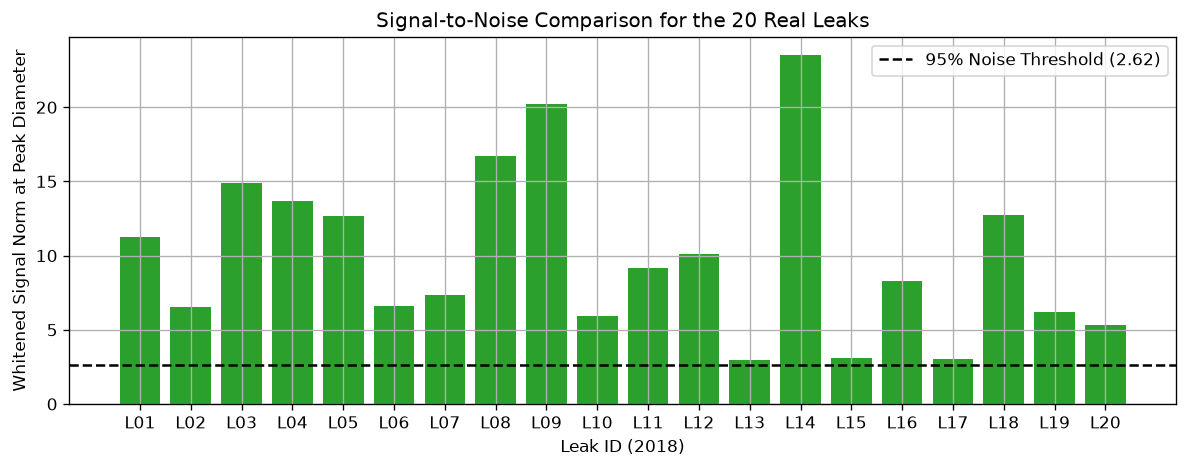

In [5]:
leaks_df['above_noise_95'] = leaks_df['z_at_D'] >= thr_noise
display(leaks_df[['leak_id', 'pipe_id', 'type', 'diameter_m', 'cluster', 'z_at_D', 'above_noise_95']].round(3))

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['tab:green' if ok else 'tab:red' for ok in leaks_df['above_noise_95']]
ax.bar(leaks_df['leak_id'].astype(str), leaks_df['z_at_D'], color=colors)
ax.axhline(thr_noise, color='black', linestyle='--', label=f'95% Noise Threshold ({thr_noise:.2f})')
ax.set_xlabel('Leak ID (2018)')
ax.set_ylabel('Whitened Signal Norm at Peak Diameter')
ax.set_title('Signal-to-Noise Comparison for the 20 Real Leaks')
ax.legend()
plt.tight_layout()
plt.show()

## ۵. مصورسازی توپولوژی شبکه L-Town، خوشه‌های لوله‌ها و موقعیت حسگرها

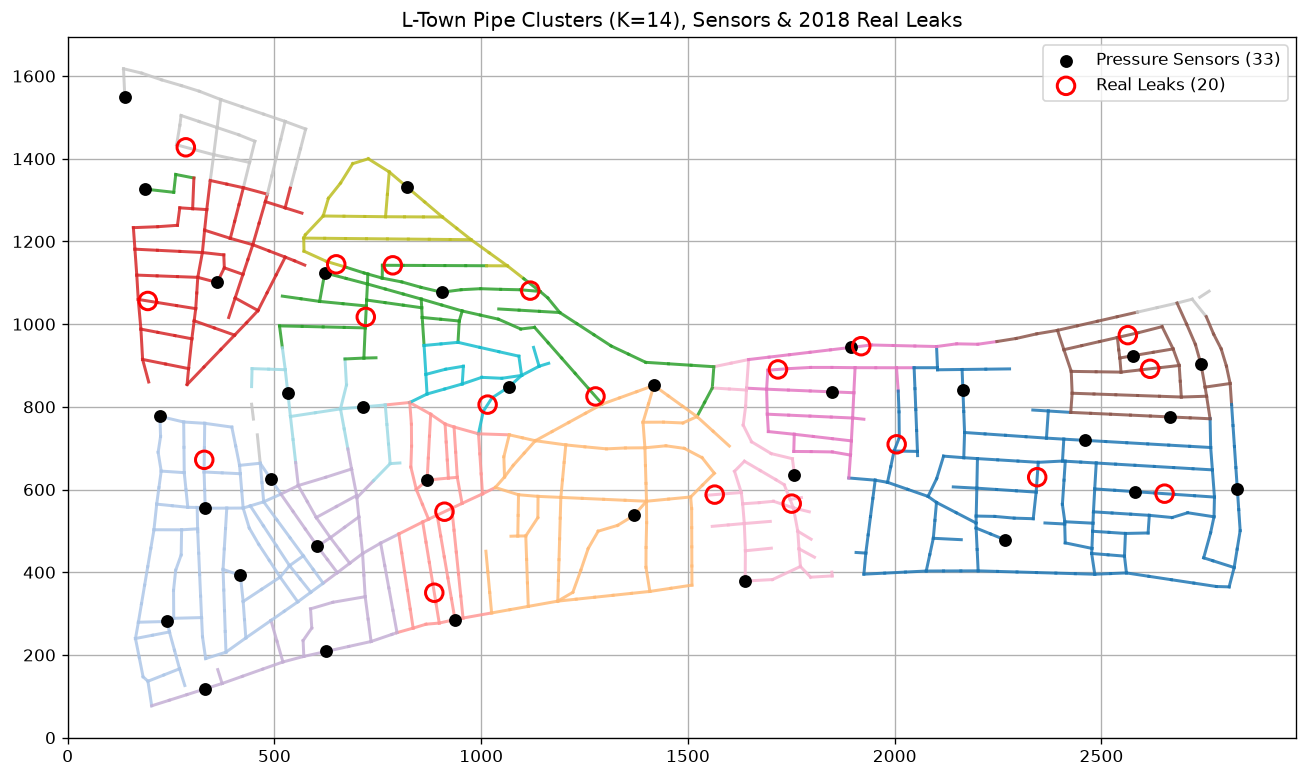

In [8]:
wn = wntr.network.WaterNetworkModel(INP)
sg = np.load(os.path.join(ART, 'signatures.npz'))
sensors = list(sg['sensors'])
cluster_map = dict(zip(pipes_df['pipe_id'], pipes_df['cluster']))

fig, ax = plt.subplots(figsize=(11, 9))
cmap = plt.get_cmap('tab20', chosen_K)

# رسم لوله‌ها بر اساس خوشه
for name, pipe in wn.pipes():
    n1 = wn.get_node(pipe.start_node_name).coordinates
    n2 = wn.get_node(pipe.end_node_name).coordinates
    c = cluster_map[name]
    ax.plot([n1[0], n2[0]], [n1[1], n2[1]], color=cmap(c), linewidth=1.8, alpha=0.85)

# رسم گره‌های دارای حسگر فشار
sx = [wn.get_node(s).coordinates[0] for s in sensors]
sy = [wn.get_node(s).coordinates[1] for s in sensors]
ax.scatter(sx, sy, c='black', s=45, zorder=5, label='Pressure Sensors (33)')

# رسم محل ۲۰ نشت واقعی
for _, row in leaks_df.iterrows():
    pipe = wn.get_link(row['pipe_id'])
    n1 = wn.get_node(pipe.start_node_name).coordinates
    n2 = wn.get_node(pipe.end_node_name).coordinates
    mx, my = (n1[0] + n2[0]) / 2, (n1[1] + n2[1]) / 2
    ax.scatter([mx], [my], facecolors='none', edgecolors='red', s=110, linewidths=1.8, zorder=6)

ax.scatter([], [], facecolors='none', edgecolors='red', s=110, linewidths=1.8, label='Real Leaks (20)')
ax.set_title(f'L-Town Pipe Clusters (K={chosen_K}), Sensors & 2018 Real Leaks')
ax.set_aspect('equal')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()